# LSTM Indirect Solar Forecast (Residual Enhanced) — Fixed

This is a corrected notebook copy. The original notebook is not modified.
The cell order intentionally follows the original workflow: load data,
preprocess, build hourly sequences, split, train, evaluate, plot, and save.


## 1. Imports, deterministic setup, and helpers


In [1]:
from pathlib import Path
import random
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    warnings.warn("Deterministic TensorFlow operations are unavailable in this runtime.")

def find_project_root():
    """Find the repository root when Jupyter is launched from inside the repository."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "Data Download").is_dir() and (candidate / "FCNN Direct Method").is_dir():
            return candidate
    raise FileNotFoundError(
        "Cannot locate the repository root containing 'Data Download' and the method folders."
    )


PROJECT_ROOT = find_project_root()
RAW_DATA_DIR = PROJECT_ROOT / "Data Download"
FIXED_DATA_DIR = PROJECT_ROOT / "fixed_data"
DATA_FILE = FIXED_DATA_DIR / "ercot_2021_2024_hourly.csv"
OUTPUT_DIR = PROJECT_ROOT / "fixed_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TIME_COLUMN = "time"


In [2]:
def dense_one_hot():
    """Support both current and older scikit-learn OneHotEncoder APIs."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def detect_time_column(frame, value_columns):
    preferred = [
        "Time (Hour-Ending)", "time", "Time", "timestamp", "Timestamp",
        "datetime", "Datetime", "date", "Date",
    ]
    for column in preferred:
        if column in frame.columns:
            return column
    values = set(value_columns)
    candidates = [
        column for column in frame.columns
        if column not in values
        and ("time" in str(column).lower() or "date" in str(column).lower())
    ]
    if len(candidates) == 1:
        return candidates[0]
    other_columns = [column for column in frame.columns if column not in values]
    return other_columns[0] if len(other_columns) == 1 else None


def read_source(filename, column_mapping, reference_time=None):
    """Read selected values and preserve/validate their timestamps."""
    path = DATA_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Required input file not found: {path.resolve()}")
    raw = pd.read_excel(path)
    missing = [column for column in column_mapping if column not in raw.columns]
    if missing:
        raise KeyError(f"{filename} is missing columns: {missing}")

    time_column = detect_time_column(raw, column_mapping.keys())
    if time_column is None:
        if reference_time is None or len(raw) != len(reference_time):
            raise ValueError(
                f"{filename} has no usable timestamp and cannot be safely aligned."
            )
        warnings.warn(
            f"{filename} has no detectable timestamp; attaching the validated "
            "canonical timeline. Add timestamps to remove this fallback."
        )
        time_values = reference_time.reset_index(drop=True)
    else:
        time_values = raw[time_column]

    result = pd.DataFrame({TIME_COLUMN: pd.to_datetime(time_values, errors="coerce")})
    for source_column, output_column in column_mapping.items():
        result[output_column] = pd.to_numeric(raw[source_column], errors="coerce")
    invalid = result.isna().any(axis=1)
    if invalid.any():
        warnings.warn(f"Dropping {int(invalid.sum())} invalid rows from {filename}.")
        result = result.loc[~invalid].copy()
    result = result.sort_values(TIME_COLUMN).reset_index(drop=True)
    if result[TIME_COLUMN].duplicated().any():
        raise ValueError(
            f"{filename} contains duplicate timestamps. Resolve timezone/DST "
            "ambiguity instead of dropping duplicates."
        )
    return result


def merge_sources(base, labelled_sources):
    """Perform explicit one-to-one timestamp joins and report any row loss."""
    merged = base.copy()
    for label, source in labelled_sources:
        before = len(merged)
        merged = merged.merge(source, on=TIME_COLUMN, how="inner", validate="one_to_one")
        if len(merged) != before or len(merged) != len(source):
            print(
                f"Timestamp intersection with {label}: master {before}, "
                f"source {len(source)}, retained {len(merged)}"
            )
    if merged.empty:
        raise ValueError("No common timestamps remain after input alignment.")
    return merged.sort_values(TIME_COLUMN).reset_index(drop=True)


def make_sequences(feature_values, target_values, timestamps, history_hours=24):
    """Create only windows whose every adjacent timestamp is exactly one hour apart."""
    X, y, target_times, target_positions = [], [], [], []
    one_hour = pd.Timedelta(hours=1)
    for target_position in range(history_hours, len(timestamps)):
        start = target_position - history_hours
        window_times = timestamps.iloc[start:target_position + 1]
        if not window_times.diff().iloc[1:].eq(one_hour).all():
            continue
        X.append(feature_values[start:target_position].copy())
        y.append(target_values[target_position])
        target_times.append(timestamps.iloc[target_position])
        target_positions.append(target_position)
    if not X:
        raise ValueError("No continuous hourly forecasting windows were found.")
    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32).reshape(-1, 1),
        pd.DatetimeIndex(target_times),
        np.asarray(target_positions, dtype=np.int64),
    )


def regression_metrics(actual, predicted, mape_min_actual=1.0):
    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)
    if actual.shape != predicted.shape or actual.size == 0:
        raise ValueError("Actual and predicted arrays must have the same non-zero length.")
    if not np.isfinite(actual).all() or not np.isfinite(predicted).all():
        raise ValueError("Metrics require finite values.")
    error = predicted - actual
    mse = mean_squared_error(actual, predicted)
    variance = np.var(actual)
    smape_denominator = np.abs(actual) + np.abs(predicted)
    smape_terms = np.divide(
        2.0 * np.abs(error), smape_denominator,
        out=np.zeros_like(smape_denominator), where=smape_denominator > 1e-9,
    )
    mape_mask = np.abs(actual) > mape_min_actual
    return {
        "sample_count": int(actual.size),
        "mean_error_mw": float(np.mean(error)),
        "mae_mw": float(mean_absolute_error(actual, predicted)),
        "rmse_mw": float(np.sqrt(mse)),
        "mse_mw2": float(mse),
        "nmse": float(mse / variance) if variance > 1e-12 else np.nan,
        "r2": float(r2_score(actual, predicted)),
        "smape_percent": float(np.mean(smape_terms) * 100.0),
        "masked_mape_percent": (
            float(np.mean(np.abs(error[mape_mask] / actual[mape_mask])) * 100.0)
            if mape_mask.any() else np.nan
        ),
        "mape_min_actual_mw": float(mape_min_actual),
        "mape_sample_count": int(mape_mask.sum()),
    }


## 2. Timestamp-aligned solar and irradiance data


In [3]:
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f"Prepared data not found: {DATA_FILE}\n"
        "Run Data Preparation/01_Prepare_Available_ERCOT_Data.ipynb first."
    )

load_data = pd.read_csv(DATA_FILE, parse_dates=[TIME_COLUMN])
required_columns = {
    TIME_COLUMN, "total_load", "solar_generation", "solar_installed",
    "wind_generation", "wind_installed", "net_load", "clear_sky_proxy",
}
missing_columns = required_columns.difference(load_data.columns)
if missing_columns:
    raise KeyError(f"Prepared data is missing columns: {sorted(missing_columns)}")
if load_data[TIME_COLUMN].duplicated().any():
    raise ValueError("Prepared data contains duplicate timestamps.")
load_data = load_data.sort_values(TIME_COLUMN).reset_index(drop=True)
print("Prepared data:", DATA_FILE)
print("Shape:", load_data.shape)
print("Range:", load_data[TIME_COLUMN].min(), "to", load_data[TIME_COLUMN].max())
load_data.head()


df = load_data[[
    TIME_COLUMN, "solar_generation", "solar_installed", "clear_sky_proxy"
]].copy()

# Common boundaries are fixed before lag rows are removed.
validation_start = df.loc[int(len(df) * 0.90), TIME_COLUMN]
test_start = df.loc[int(len(df) * 0.95), TIME_COLUMN]
eps = 1e-6
df["target_cf"] = (
    df["solar_generation"] / (df["solar_installed"] + eps)
).clip(0.0, 1.05)
local_time = df[TIME_COLUMN].dt.tz_localize("UTC").dt.tz_convert("America/Chicago")
df["hour"] = local_time.dt.hour
df["dayofyear"] = local_time.dt.dayofyear
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24.0)
df["doy_sin"] = np.sin(2 * np.pi * df["dayofyear"] / 365.25)
df["doy_cos"] = np.cos(2 * np.pi * df["dayofyear"] / 365.25)
df["is_daylight"] = (df["clear_sky_proxy"] > 1e-4).astype(float)
df.head()


Prepared data: c:\Users\lfang7\Project\Report\Conference paper\2026 SmartGridComm\Final Code\Fixed Methods\fixed_data\ercot_2021_2024_hourly.csv
Shape: (35065, 8)
Range: 2021-01-01 06:00:00 to 2025-01-01 06:00:00


,time,solar_generation,solar_installed,clear_sky_proxy,target_cf,hour,dayofyear,hour_sin,hour_cos,doy_sin,doy_cos,is_daylight
0,2021-01-01 06:00:00,0.00907,5649,0.0,0.000002,0,1,0.000000,1.000000,0.017202,0.999852,0.0
1,2021-01-01 07:00:00,0.00907,5649,0.0,0.000002,1,1,0.258819,0.965926,0.017202,0.999852,0.0
2,2021-01-01 08:00:00,0.00907,5649,0.0,0.000002,2,1,0.500000,0.866025,0.017202,0.999852,0.0
3,2021-01-01 09:00:00,0.00907,5649,0.0,0.000002,3,1,0.707107,0.707107,0.017202,0.999852,0.0
4,2021-01-01 10:00:00,0.00907,5649,0.0,0.000002,4,1,0.866025,0.500000,0.017202,0.999852,0.0


## 3. Time-based lags and residual target


In [4]:
# Critical fix: lags are joined by timestamp, not by row position.
lag_source = df[[TIME_COLUMN, "target_cf", "clear_sky_proxy"]].copy()
for lag in [1, 2, 24, 48]:
    lagged = lag_source.copy()
    lagged[TIME_COLUMN] = lagged[TIME_COLUMN] + pd.Timedelta(hours=lag)
    lagged = lagged.rename(columns={
        "target_cf": f"cf_lag_{lag}",
        "clear_sky_proxy": f"sky_lag_{lag}",
    })
    df = df.merge(lagged, on=TIME_COLUMN, how="left", validate="one_to_one")

df["cf_persist_24"] = df["cf_lag_24"]
df["residual_target"] = df["target_cf"] - df["cf_persist_24"]
df = df.dropna().sort_values(TIME_COLUMN).reset_index(drop=True)
df.head()


,time,solar_generation,solar_installed,clear_sky_proxy,target_cf,hour,dayofyear,hour_sin,hour_cos,doy_sin,...,cf_lag_1,sky_lag_1,cf_lag_2,sky_lag_2,cf_lag_24,sky_lag_24,cf_lag_48,sky_lag_48,cf_persist_24,residual_target
0,2021-01-03 06:00:00,0.029298,5649,0.0,0.000005,0,3,0.000000,1.000000,0.051584,...,0.000005,0.0,0.000005,0.0,0.000004,0.0,0.000002,0.0,0.000004,0.000001
1,2021-01-03 07:00:00,0.029298,5649,0.0,0.000005,1,3,0.258819,0.965926,0.051584,...,0.000005,0.0,0.000005,0.0,0.000004,0.0,0.000002,0.0,0.000004,0.000001
2,2021-01-03 08:00:00,0.029298,5649,0.0,0.000005,2,3,0.500000,0.866025,0.051584,...,0.000005,0.0,0.000005,0.0,0.000004,0.0,0.000002,0.0,0.000004,0.000001
3,2021-01-03 09:00:00,0.029298,5649,0.0,0.000005,3,3,0.707107,0.707107,0.051584,...,0.000005,0.0,0.000005,0.0,0.000004,0.0,0.000002,0.0,0.000004,0.000001
4,2021-01-03 10:00:00,0.029298,5649,0.0,0.000005,4,3,0.866025,0.500000,0.051584,...,0.000005,0.0,0.000005,0.0,0.000004,0.0,0.000002,0.0,0.000004,0.000001


## 4. Training-only scaling and continuous sequences


In [5]:
feature_columns = [
    "target_cf", "clear_sky_proxy",
    "cf_lag_1", "cf_lag_2", "cf_lag_24", "cf_lag_48",
    "sky_lag_1", "sky_lag_2", "sky_lag_24", "sky_lag_48",
    "hour_sin", "hour_cos", "doy_sin", "doy_cos", "is_daylight",
]
continuous_columns = feature_columns[:10]
training_rows = df[TIME_COLUMN] < validation_start
x_scaler = StandardScaler().fit(df.loc[training_rows, continuous_columns])
y_scaler = StandardScaler().fit(df.loc[training_rows, ["residual_target"]])

scaled = df.copy()
scaled[continuous_columns] = x_scaler.transform(df[continuous_columns])
scaled["residual_target_scaled"] = y_scaler.transform(df[["residual_target"]])
feature_values = scaled[feature_columns].to_numpy(dtype=np.float32)
target_values = scaled["residual_target_scaled"].to_numpy(dtype=np.float32)

X, Y, target_times, target_positions = make_sequences(
    feature_values, target_values, df[TIME_COLUMN], history_hours=24
)
train_mask = target_times < validation_start
validation_mask = (target_times >= validation_start) & (target_times < test_start)
test_mask = target_times >= test_start
X_train, Y_train = X[train_mask], Y[train_mask]
X_val, Y_val = X[validation_mask], Y[validation_mask]
X_test, Y_test = X[test_mask], Y[test_mask]
test_times = target_times[test_mask]
test_positions = target_positions[test_mask]
if min(len(X_train), len(X_val), len(X_test)) == 0:
    raise ValueError("At least one chronological partition is empty.")
print(X_train.shape, X_val.shape, X_test.shape)


(31486, 24, 15) (1753, 24, 15) (1754, 24, 15)


## 5. Residual LSTM with best-weight restoration


In [6]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1], X_train.shape[2])),
    keras.layers.LSTM(64, return_sequences=True),
    keras.layers.Dropout(0.15),
    keras.layers.LSTM(32),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dropout(0.10),
    keras.layers.Dense(1),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.Huber(),
    metrics=["mae", "mse"],
)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6),
]
train_positions = target_positions[train_mask]
train_actual_cf = df.iloc[train_positions]["target_cf"].to_numpy(dtype=float)
train_residual = df.iloc[train_positions]["residual_target"].to_numpy(dtype=float)
sample_weight = 1.0 + 1.5 * (train_actual_cf > 0.02) + 1.5 * (np.abs(train_residual) > 0.03)
history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    sample_weight=sample_weight,
    epochs=80,
    batch_size=64,
    shuffle=False,
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/80
492/492 [==============================] - 20s 24ms/step - loss: 0.8193 - mae: 0.4290 - mse: 0.6218 - val_loss: 0.0562 - val_mae: 0.1924 - val_mse: 0.1161 - lr: 0.0010
Epoch 2/80
492/492 [==============================] - 10s 20ms/step - loss: 0.4634 - mae: 0.3052 - mse: 0.3031 - val_loss: 0.0284 - val_mae: 0.1408 - val_mse: 0.0571 - lr: 0.0010
Epoch 3/80
492/492 [==============================] - 10s 20ms/step - loss: 0.3092 - mae: 0.2385 - mse: 0.1867 - val_loss: 0.0218 - val_mae: 0.1214 - val_mse: 0.0437 - lr: 0.0010
Epoch 4/80
492/492 [==============================] - 10s 20ms/step - loss: 0.2629 - mae: 0.2151 - mse: 0.1539 - val_loss: 0.0240 - val_mae: 0.1226 - val_mse: 0.0481 - lr: 0.0010
Epoch 5/80
492/492 [==============================] - 10s 20ms/step - loss: 0.2487 - mae: 0.2065 - mse: 0.1450 - val_loss: 0.0183 - val_mae: 0.1066 - val_mse: 0.0367 - lr: 0.0010
Epoch 6/80
492/492 [==============================] - 14s 28ms/step - loss: 0.2296 - mae: 0.1957 - mse: 0

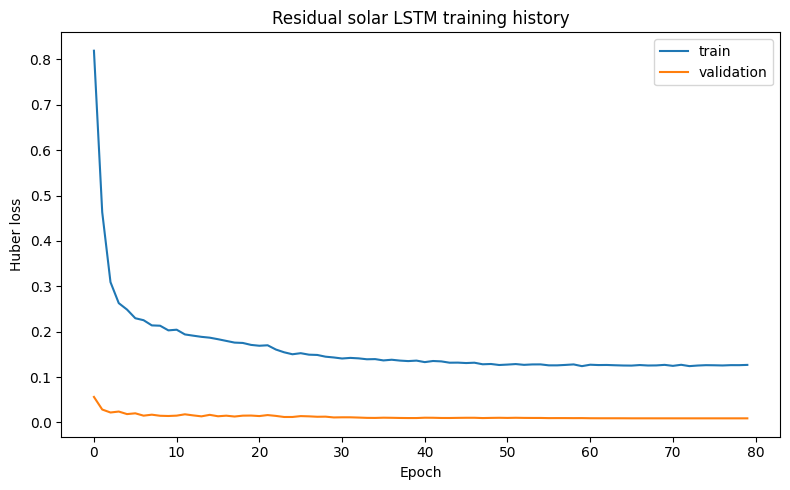

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Huber loss")
plt.title("Residual solar LSTM training history")
plt.legend()
plt.tight_layout()
plt.show()


## 6. Physical predictions and zero-safe metrics


In [8]:
predicted_residual_scaled = model.predict(X_test, verbose=0).reshape(-1, 1)
predicted_residual = y_scaler.inverse_transform(predicted_residual_scaled).ravel()
test_rows = df.iloc[test_positions]
predicted_cf = np.clip(
    test_rows["cf_persist_24"].to_numpy(dtype=float) + predicted_residual,
    0.0,
    1.05,
)
predicted_mw = predicted_cf * test_rows["solar_installed"].to_numpy(dtype=float)
actual_mw = test_rows["solar_generation"].to_numpy(dtype=float)
predictions = pd.DataFrame({
    TIME_COLUMN: test_times,
    "actual": actual_mw,
    "predict": predicted_mw,
})
predictions["error"] = predictions["predict"] - predictions["actual"]
predictions["absolute_error"] = predictions["error"].abs()
metrics = regression_metrics(predictions["actual"], predictions["predict"], mape_min_actual=50.0)
pd.Series(metrics)


sample_count             1754.000000
mean_error_mw             -10.173434
mae_mw                    254.991009
rmse_mw                   530.398127
mse_mw2                281322.172975
nmse                        0.006735
r2                          0.993265
smape_percent             104.906047
masked_mape_percent        18.206178
mape_min_actual_mw         50.000000
mape_sample_count         813.000000
dtype: float64

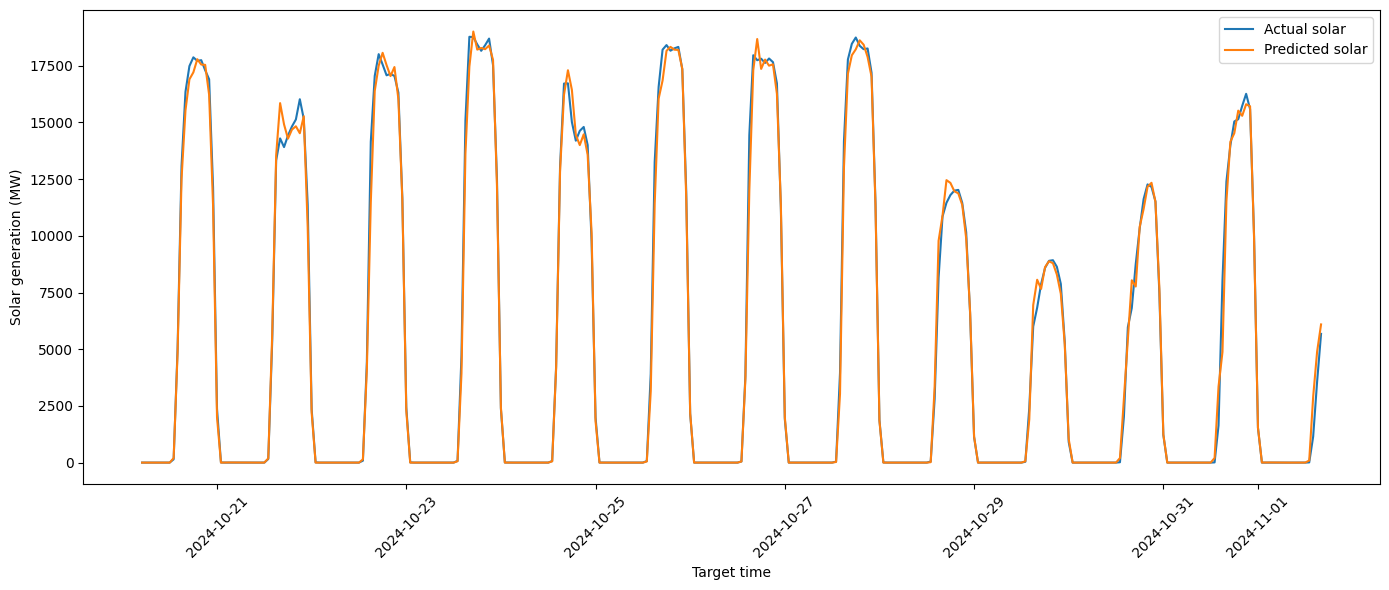

In [9]:
view = predictions.iloc[:min(300, len(predictions))]
plt.figure(figsize=(14, 6))
plt.plot(view[TIME_COLUMN], view["actual"], label="Actual solar")
plt.plot(view[TIME_COLUMN], view["predict"], label="Predicted solar")
plt.xlabel("Target time")
plt.ylabel("Solar generation (MW)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


## 7. Save unique artifacts


In [ ]:
ARTIFACT_NAME = "lstm_indirect_solar_generation"
model.save(OUTPUT_DIR / f"{ARTIFACT_NAME}.keras")
joblib.dump(
    {
        "x_scaler": x_scaler,
        "y_scaler": y_scaler,
        "feature_columns": feature_columns,
        "validation_start": validation_start,
        "test_start": test_start,
    },
    OUTPUT_DIR / f"{ARTIFACT_NAME}_preprocessing.joblib",
)
pd.DataFrame(history.history).to_csv(
    OUTPUT_DIR / f"{ARTIFACT_NAME}_training_history.csv", index=False
)
predictions.to_csv(OUTPUT_DIR / f"{ARTIFACT_NAME}_predictions.csv", index=False)
predictions.to_excel(OUTPUT_DIR / f"{ARTIFACT_NAME}_predictions.xlsx", index=False)
pd.Series(metrics).to_json(OUTPUT_DIR / f"{ARTIFACT_NAME}_metrics.json", indent=2)
print("Saved:", OUTPUT_DIR / f"{ARTIFACT_NAME}_predictions.xlsx")
